# ECE 3715 Mini-Project 1

## Probability, Bayes, and Discrete Random Variables
Team Members: Brandon Chie, Octavio Reyna, William Hsu

Professor: Dr. Nir Regev

Due Date: October 9, 2026
## Objective
Use probability theory and Python simulations to analyze a wireless communication link. Each bit is independently corrupted by the channel with probability \(p\). We will determine how these corrupted bits affect packet errors and retransmissions.

In [39]:
%load_ext autoreload
%autoreload 2

import time
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import mp1lib as lib

T_START = time.time()     # print elapsed time in the last cell for the README

SEED = 17                  # seed number is our team number
rng = np.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [40]:
rng_test = np.random.default_rng(12345)   # separate generator so tests don't shift step streams

# bsc: p=0 changes nothing, p=1 flips everything
b = np.array([0, 1, 1, 0, 1])
assert np.array_equal(lib.bsc(b, 0.0, rng_test), b)
assert np.array_equal(lib.bsc(b, 1.0, rng_test), 1 - b)
print("bsc: p=0 ->", lib.bsc(b, 0.0, rng_test), " p=1 ->", lib.bsc(b, 1.0, rng_test))

# packet_errors: p=0 gives 0 errors, p=1 gives n_bits errors
assert np.all(lib.packet_errors(5, 1000, 0.0, rng_test) == 0)
assert np.all(lib.packet_errors(5, 1000, 1.0, rng_test) == 1000)
print("packet_errors: p=0 ->", lib.packet_errors(3, 1000, 0.0, rng_test),
      " p=1 ->", lib.packet_errors(3, 1000, 1.0, rng_test))

# attempts_until_clean: q=1 means every packet clean on attempt 1; support never includes 0
assert np.all(lib.attempts_until_clean(5, 1.0, rng_test) == 1)
assert lib.attempts_until_clean(10_000, 0.3, rng_test).min() >= 1
print("attempts_until_clean: q=1 ->", lib.attempts_until_clean(3, 1.0, rng_test))

# tv_distance: identical -> 0, disjoint -> 1, a hand-computable middle case -> 0.5
assert lib.tv_distance([0.2, 0.3, 0.5], [0.2, 0.3, 0.5]) == 0.0
assert lib.tv_distance([1, 0, 0], [0, 0, 1]) == 1.0
assert np.isclose(lib.tv_distance([0.5, 0.5], [1.0, 0.0]), 0.5)
print("tv_distance: identical=0, disjoint=1, [.5,.5] vs [1,0] =",
      lib.tv_distance([0.5, 0.5], [1.0, 0.0]))

print("\nAll library tests passed.")

bsc: p=0 -> [0 1 1 0 1]  p=1 -> [1 0 0 1 0]
packet_errors: p=0 -> [0 0 0]  p=1 -> [1000 1000 1000]
attempts_until_clean: q=1 -> [1 1 1]
tv_distance: identical=0, disjoint=1, [.5,.5] vs [1,0] = 0.5

All library tests passed.


## Step 1: Sample Space and Probability Axioms

We consider a 4-bit packet where each bit is independently corrupted with
probability $p=0.1$. A corrupted bit is represented by 1, and an
uncorrupted bit is represented by 0.

The three events are:

- $A$: at least one error among the first two bits.
- $B$: exactly two errors in the packet.
- $C$: the fourth bit is corrupted.

There are $2^4=16$ possible error patterns. The probability of a pattern
with $k$ errors is

$$
P(\text{pattern})=p^k(1-p)^{4-k}.
$$

In [41]:
from itertools import product

p_step1 = 0.1

# Enumerate all 16 possible four-bit error patterns
patterns = np.array(list(product([0, 1], repeat=4)))

# Count the number of errors in each pattern
number_of_errors = patterns.sum(axis=1)

# Calculate the exact probability of each pattern
pattern_probabilities = (
    p_step1 ** number_of_errors
    * (1 - p_step1) ** (4 - number_of_errors)
)

print("Number of patterns:", len(patterns))
print("Sum of exact probabilities:", pattern_probabilities.sum())

Number of patterns: 16
Sum of exact probabilities: 0.9999999999999999


In [42]:
# Define the three events

# A: at least one error among the first two bits
A = patterns[:, 0:2].any(axis=1)

# B: exactly two errors in the entire packet
B = patterns.sum(axis=1) == 2

# C: the fourth bit is corrupted
C = patterns[:, 3] == 1

# Calculate exact event probabilities
P_A = pattern_probabilities[A].sum()
P_B = pattern_probabilities[B].sum()
P_C = pattern_probabilities[C].sum()

print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(C) = {P_C:.4f}")

P(A) = 0.1900
P(B) = 0.0486
P(C) = 0.1000


### Exact Event Intersections

The pairwise intersections are found by requiring two events to occur
simultaneously. The triple intersection requires all three events to occur.

$$
P(A\cap B), \quad P(A\cap C), \quad P(B\cap C)
$$

and

$$
P(A\cap B\cap C).
$$

In [43]:
# Calculate exact intersection probabilities

P_AB = pattern_probabilities[A & B].sum()
P_AC = pattern_probabilities[A & C].sum()
P_BC = pattern_probabilities[B & C].sum()
P_ABC = pattern_probabilities[A & B & C].sum()

print(f"P(A and B) = {P_AB:.4f}")
print(f"P(A and C) = {P_AC:.4f}")
print(f"P(B and C) = {P_BC:.4f}")
print(f"P(A and B and C) = {P_ABC:.4f}")

P(A and B) = 0.0405
P(A and C) = 0.0190
P(B and C) = 0.0243
P(A and B and C) = 0.0162


### Inclusion-Exclusion

The probability that at least one of the events occurs is calculated using
the inclusion-exclusion formula:

$$
P(A\cup B\cup C)
=
P(A)+P(B)+P(C)
-P(A\cap B)-P(A\cap C)-P(B\cap C)
+P(A\cap B\cap C).
$$

In [44]:
# Calculate the union directly
P_union_direct = pattern_probabilities[A | B | C].sum()

# Calculate the union using inclusion-exclusion
P_union_inclusion_exclusion = (
    P_A + P_B + P_C
    - P_AB - P_AC - P_BC
    + P_ABC
)

print(f"P(A or B or C), direct = {P_union_direct:.4f}")
print(
    f"P(A or B or C), inclusion-exclusion = "
    f"{P_union_inclusion_exclusion:.4f}"
)

P(A or B or C), direct = 0.2710
P(A or B or C), inclusion-exclusion = 0.2710


### Monte Carlo Simulation

We now estimate the event probabilities by simulating $N=10^6$ four-bit
packets. Each bit is independently corrupted with probability $p=0.1$.
The simulated probabilities are calculated as the fraction of packets for
which each event occurs.

For an estimated probability $\hat{P}$, the standard error is

$$
SE=\sqrt{\frac{\hat{P}(1-\hat{P})}{N}}.
$$

In [45]:
# Monte Carlo simulation
N = 1_000_000

# Start with packets containing no errors, then apply the BSC
simulated_patterns = lib.bsc(
    np.zeros((N, 4), dtype=int),
    p_step1,
    rng1
)

# Define simulated events
sim_A = simulated_patterns[:, 0:2].any(axis=1)
sim_B = simulated_patterns.sum(axis=1) == 2
sim_C = simulated_patterns[:, 3] == 1

# Simulated intersections and union
sim_AB = sim_A & sim_B
sim_AC = sim_A & sim_C
sim_BC = sim_B & sim_C
sim_ABC = sim_A & sim_B & sim_C
sim_union = sim_A | sim_B | sim_C

# Event names
event_names = [
    "A",
    "B",
    "C",
    "A and B",
    "A and C",
    "B and C",
    "A and B and C",
    "A or B or C"
]

# Exact probabilities
exact_values = np.array([
    P_A,
    P_B,
    P_C,
    P_AB,
    P_AC,
    P_BC,
    P_ABC,
    P_union_inclusion_exclusion
])

# Empirical probabilities
empirical_values = np.array([
    sim_A.mean(),
    sim_B.mean(),
    sim_C.mean(),
    sim_AB.mean(),
    sim_AC.mean(),
    sim_BC.mean(),
    sim_ABC.mean(),
    sim_union.mean()
])

# Standard errors and differences
standard_errors = np.sqrt(
    empirical_values * (1 - empirical_values) / N
)

differences = np.abs(empirical_values - exact_values)

print(f"{'Event':<15} {'Exact':>10} {'Empirical':>12} "
      f"{'Difference':>12} {'SE':>12} {'Within 3 SE':>14}")

for name, exact, empirical, difference, se in zip(
    event_names,
    exact_values,
    empirical_values,
    differences,
    standard_errors
):
    print(
        f"{name:<15} {exact:>10.4f} {empirical:>12.4f} "
        f"{difference:>12.4e} {se:>12.4e} "
        f"{difference <= 3 * se!s:>14}"
    )

Event                Exact    Empirical   Difference           SE    Within 3 SE
A                   0.1900       0.1905   4.9600e-04   3.9269e-04           True
B                   0.0486       0.0487   1.0800e-04   2.1526e-04           True
C                   0.1000       0.1001   7.4000e-05   3.0010e-04           True
A and B             0.0405       0.0407   2.1000e-04   1.9762e-04           True
A and C             0.0190       0.0191   1.0400e-04   1.3689e-04           True
B and C             0.0243       0.0242   5.1000e-05   1.5382e-04           True
A and B and C       0.0162       0.0163   5.1000e-05   1.2644e-04           True
A or B or C         0.2710       0.2715   4.6600e-04   4.4472e-04           True


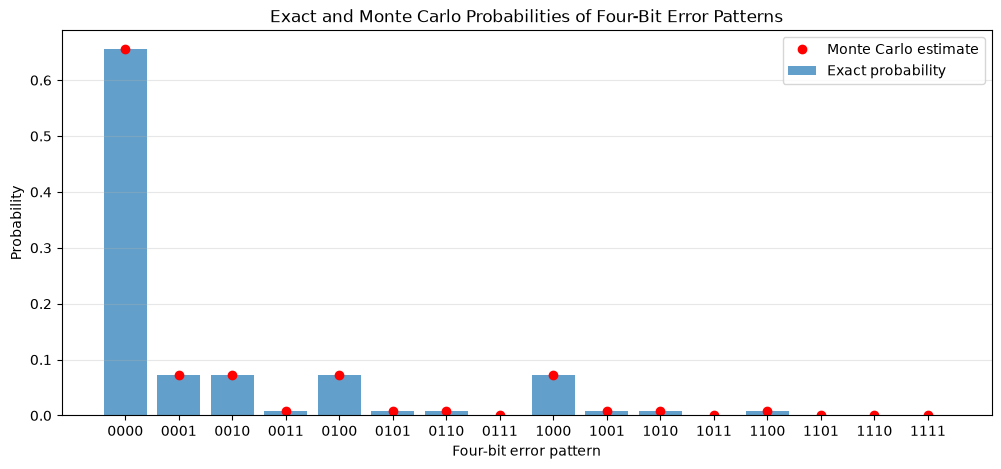

Maximum absolute difference: 0.000455


In [46]:
# Calculate simulated probability for each of the 16 patterns

pattern_labels = [
    "".join(str(bit) for bit in pattern)
    for pattern in patterns
]

# Convert each four-bit pattern to an index from 0 to 15
pattern_indices = simulated_patterns @ np.array([8, 4, 2, 1])

# Count simulated occurrences and divide by N
simulated_pattern_probabilities = (
    np.bincount(pattern_indices, minlength=16) / N
)

# Plot exact probabilities as bars
x = np.arange(16)

plt.figure(figsize=(12, 5))

plt.bar(
    x,
    pattern_probabilities,
    alpha=0.7,
    label="Exact probability"
)

plt.plot(
    x,
    simulated_pattern_probabilities,
    "o",
    color="red",
    label="Monte Carlo estimate"
)

plt.xticks(x, pattern_labels)
plt.xlabel("Four-bit error pattern")
plt.ylabel("Probability")
plt.title("Exact and Monte Carlo Probabilities of Four-Bit Error Patterns")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

max_difference = np.max(
    np.abs(pattern_probabilities - simulated_pattern_probabilities)
)

print(f"Maximum absolute difference: {max_difference:.6f}")

### Figure 1 Interpretation

The exact probabilities are shown by the bars, while the red markers show
the Monte Carlo estimates from \(10^6\) simulated packets. The estimates
closely follow the exact probabilities for all 16 error patterns. Small
differences occur because the simulation uses a finite number of random
packets. The maximum absolute difference was reported above.

### Standard Error and Step 1 Conclusion

For an event estimated using $N$ simulated packets, the standard error of
the estimated probability is

$$
SE=\sqrt{\frac{\hat{P}(1-\hat{P})}{N}},
$$

where $\hat{P}$ is the simulated probability and

$$
N=10^6.
$$

The exact and empirical probabilities are close for all of the individual
events, intersections, and their union. The comparison table shows that every
absolute difference is within three standard errors of the theoretical value.
Therefore, the Monte Carlo simulator agrees with the exact probability
calculations.

The inclusion-exclusion result also agrees with the direct union calculation:

$$
P(A\cup B\cup C)=0.2710.
$$

This confirms that the event definitions and the probability calculations are
consistent.

## Step 2: Conditional Probability and Bayes